# FDA food recalls: what drives them, and can we triage them?

**Purpose.** This notebook answers four questions a food safety team would ask, using the outputs of this repository's pipeline (extract, transform, validate, model, load):

1. Are recalls rising, and is the serious share changing?
2. Which hazards cause recalls, and which are most dangerous?
3. Where are recalling firms based?
4. How far can the recall-class model be trusted?

**Data.** openFDA food enforcement API, 29,609 records extracted on 24 November 2026 (FDA data updated 11 November 2026). After validation, 29,607 records were clean and 2 were quarantined because FDA has not classified them yet.

**Disclaimer.** openFDA states that its data is unvalidated and must not be used to make decisions about medical care.

The notebook only reads files the pipeline committed to `data/processed`; it does no cleaning of its own, so the pipeline stays the single source of truth.

## 1. Set-up and data

In [1]:
import json
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.io as pio
import yaml

# Interactive charts in VS Code, plus a static image so the charts also show on GitHub
pio.renderers.default = "plotly_mimetype+png"

# Find the project root (the folder holding config.yaml), wherever the notebook is opened from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
config = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
PROCESSED = ROOT / config["paths"]["processed"]
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

DATES = ["recall_initiation_date", "center_classification_date", "report_date", "termination_date"]
recalls = pd.read_csv(PROCESSED / "recalls_clean.csv", parse_dates=DATES, low_memory=False)
metrics = json.loads((PROCESSED / "metrics.json").read_text(encoding="utf-8"))
pending = pd.read_csv(PROCESSED / "pending_predictions.csv")

CLASS_ORDER = ["I", "II", "III"]
CLASS_COLOURS = {"I": "#D55E00", "II": "#E69F00", "III": "#0072B2"}  # Okabe-Ito palette: colour-blind safe

print(f"{len(recalls):,} recalled products in {recalls['event_id'].nunique():,} recall events, "
      f"reported {recalls['report_date'].min():%b %Y} to {recalls['report_date'].max():%b %Y}")

29,607 recalled products in 7,955 recall events, reported Jun 2012 to Nov 2026


## 2. From products to recall events

FDA classifies each recalled **product**, but one recall **event** (a single firm action) can cover many products: here the largest covers 409. Counting products would let a handful of big recalls dominate every chart, so the plots count **events**. Each event takes its **most serious** class, its most common hazard and the recalling firm's location.

In [2]:
severity = {"I": 1, "II": 2, "III": 3}
classified = recalls[recalls["classification"].isin(CLASS_ORDER)].copy()
classified["severity"] = classified["classification"].map(severity)

events = (classified.sort_values("severity")
          .groupby("event_id", as_index=False)
          .agg(classification=("classification", "first"),
               hazard=("hazard", lambda s: s.mode().iat[0]),
               state=("state", "first"),
               country=("country", "first"),
               report_date=("report_date", "min"),
               products=("recall_number", "size")))

print(f"{len(events):,} events; median {events['products'].median():.0f} product per event, "
      f"largest {events['products'].max()}")
print("Share of events by class:", events["classification"].value_counts(normalize=True).round(3).to_dict())

7,955 events; median 1 product per event, largest 409
Share of events by class: {'II': 0.506, 'I': 0.412, 'III': 0.081}


## 3. Are recalls rising, and is the serious share changing?

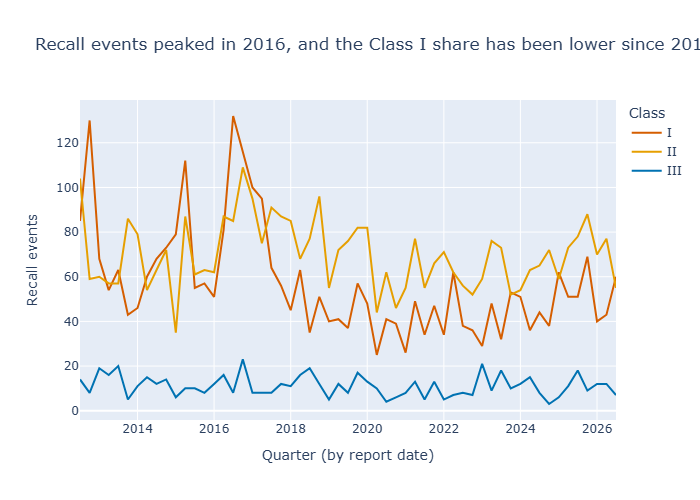

In [3]:
first_full, last_full = pd.Period("2012Q3"), pd.Timestamp.today().to_period("Q") - 1
trend = (events.assign(quarter=events["report_date"].dt.to_period("Q"))
         .query("@first_full <= quarter <= @last_full")
         .groupby(["quarter", "classification"]).size().rename("events").reset_index())
trend["quarter"] = trend["quarter"].dt.to_timestamp()

fig1 = px.line(trend, x="quarter", y="events", color="classification",
               category_orders={"classification": CLASS_ORDER}, color_discrete_map=CLASS_COLOURS,
               labels={"quarter": "Quarter (by report date)", "events": "Recall events",
                       "classification": "Class"},
               title="Recall events peaked in 2016, and the Class I share has been lower since 2018")
fig1.show()
fig1.write_image(FIGURES / "1_trend.png", width=900, height=450, scale=2)

**What it shows.**

- **Volume peaked in 2016** at 782 events.
- **2020 was the low point** at 420 events. Fewer inspections and disrupted supply chains during COVID-19 are a likely factor.
- **Volume is recovering:** 575 events in 2025.
- **The serious share has changed.** Class I made up 42 to 52% of events each year from 2013 to 2017, but only 34 to 41% each year since 2018.

So recalls are not simply rising, and a smaller share is serious than a decade ago.

**Method notes.**

- The partial first quarter (June 2012) and the current, incomplete quarter are left out, so the line does not appear to crash.
- Report dates are used, because recently started recalls may not be classified yet.

## 4. Which hazards cause recalls, and which are most dangerous?

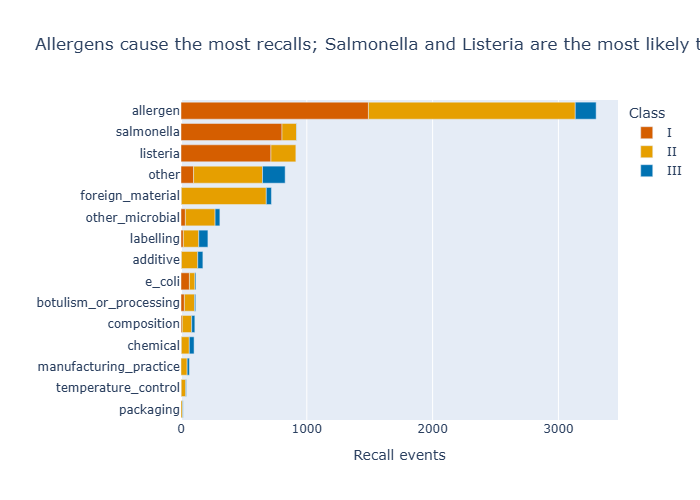

In [4]:
hazards = events.groupby(["hazard", "classification"]).size().rename("events").reset_index()

fig2 = px.bar(hazards, x="events", y="hazard", color="classification", orientation="h",
              category_orders={"classification": CLASS_ORDER}, color_discrete_map=CLASS_COLOURS,
              labels={"events": "Recall events", "hazard": "", "classification": "Class"},
              title="Allergens cause the most recalls; Salmonella and Listeria are the most likely to be Class I")
fig2.update_yaxes(categoryorder="total ascending")
fig2.show()
fig2.write_image(FIGURES / "2_hazards.png", width=900, height=550, scale=2)

**What it shows.**

- **Allergens are the biggest cause:** 3,300 of 7,955 events (41%). 45% of allergen events are Class I, because undeclared allergens can cause severe reactions.
- **Pathogens are the most dangerous per recall.** Salmonella events are 87% Class I and Listeria events 78%. Together they account for 46% of all Class I events.
- **Foreign material is common but rarely serious:** 719 events, and only 3 were Class I.

For a food safety team, allergen labelling controls and pathogen testing would prevent most serious recalls.

**Method note.** Hazards come from keyword rules on the recall reason, kept in `config.yaml`. After two rounds of tuning, 7.4% of recalled products remain in "other".

## 5. Where are recalling firms based?

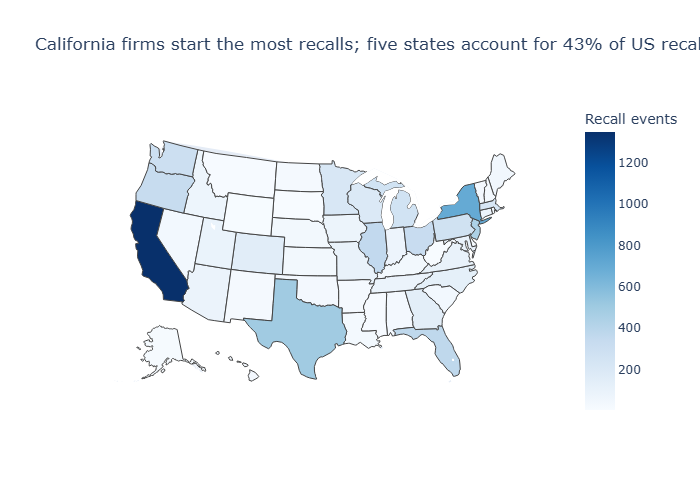

In [5]:
us_events = events[events["country"] == "United States"]
by_state = us_events.groupby("state").size().rename("events").reset_index()

fig3 = px.choropleth(by_state, locations="state", locationmode="USA-states", scope="usa",
                     color="events", color_continuous_scale="Blues",
                     labels={"events": "Recall events"},
                     title="California firms start the most recalls; five states account for 43% of US recall events")
fig3.show()
fig3.write_image(FIGURES / "3_states.png", width=900, height=500, scale=2)

**What it shows.**

- **California firms started the most recall events:** 1,350, which is 17% of US events.
- **The next four** are New York (702), Texas (498), New Jersey (444) and Florida (372).
- **Together, those five states** account for 43% of the 7,791 US events.
- **Foreign firms** started 164 events (2%), led by Canada (76).

**Caveats.**

- The map shows **where the recalling firm is based**, not where the food was sold. Many of these recalls were distributed nationwide.
- Large states have more food businesses, so counts reflect industry size as much as risk.
- A fair per-state comparison would need population or business-count data, which would be a second data source.

## 6. How far can the recall-class model be trusted?

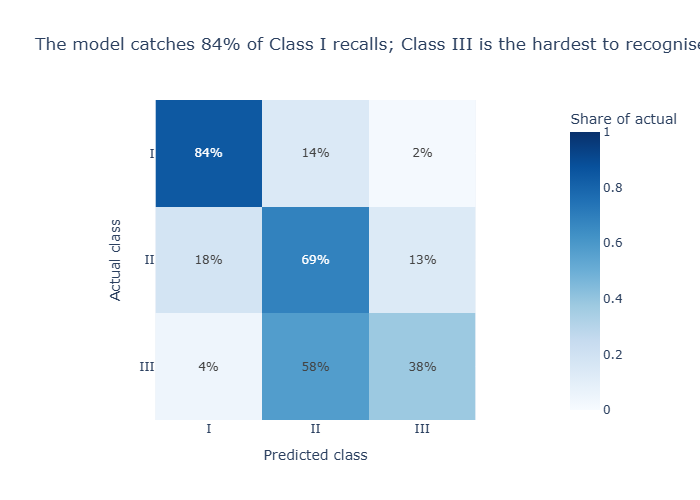

              model  accuracy  macro_f1  class_I_recall
     Majority class     0.500     0.222           0.000
       Keyword rule     0.757     0.520           0.721
Logistic regression     0.736     0.614           0.844
      Random forest     0.761     0.621           0.799


In [6]:
labels = metrics["confusion_matrix"]["labels"]
matrix = pd.DataFrame(metrics["confusion_matrix"]["matrix"], index=labels, columns=labels)
share = matrix.div(matrix.sum(axis=1), axis=0)  # each row sums to 100%

fig4 = px.imshow(share, text_auto=".0%", color_continuous_scale="Blues", zmin=0, zmax=1,
                 labels={"x": "Predicted class", "y": "Actual class", "color": "Share of actual"},
                 title="The model catches 84% of Class I recalls; Class III is the hardest to recognise")
fig4.show()
fig4.write_image(FIGURES / "4_model.png", width=600, height=500, scale=2)

print(pd.DataFrame(metrics["scores"]).to_string(index=False))

**What it shows.**

- **The selected model is logistic regression on the recall reason text plus the derived features.** It was tested on 5,921 recalls from events it never saw in training, split by recall event so that sibling products could not leak between training and test.
- **It catches 84% of Class I recalls,** against 72% for a simple keyword rule. That makes it the model with the highest Class I recall.
- **The random forest scored a fraction higher on macro F1 (0.621 against 0.614), but caught fewer Class I recalls (80%).** The model was therefore chosen by the costly error, missing a dangerous recall, rather than by a generic score.

**Trade-offs and limits.**

- **False alarms:** 18% of Class II recalls are flagged as Class I. For triage, an extra check is cheaper than a missed Class I recall.
- **Class III is hard to recognise.** Only 38% are recognised, and 58% are predicted as Class II. Class III is just 6% of the data, and the line between "unlikely to cause harm" and "may cause temporary harm" often depends on details that are not in the reason text.

### The model on live recalls

The pipeline quarantined two recalls that FDA has not classified yet. These are exactly the cases the model is for.

In [7]:
pending

,event_id,reason_for_recall,predicted,prob_I
0,99986,Potential contamination due to E. coli O26:H11.,I,0.809
1,100248,Possible Salmonella contamination.,I,0.873


Both are pathogen recalls: an E. coli O26 contamination and a possible Salmonella contamination. The model predicts both as **Class I**, with probabilities of 0.81 and 0.87, so a triage team would look at them first. FDA's eventual classification will show whether the model was right.

## 7. What this means

1. **Recalls are not simply rising.** Events peaked in 2016 (782) and fell to 420 in 2020. The Class I share has been lower since 2018, at 34 to 41% against 42 to 52% before.
2. **Most serious recalls have two causes: undeclared allergens (45% of Class I events) and Salmonella or Listeria (46%).** Prevention effort aimed at allergen labelling and pathogen testing would cover the bulk of the risk.
3. **A simple, explainable model can support triage.** It catches 84% of Class I recalls, against 72% for a keyword rule, at the cost of some false alarms. It supports FDA's experts; it does not replace them.

**Limitations.**

- **The data has gaps:** it is US-only and unvalidated.
- **The map shows where firms are based, not where food is consumed.**
- **The model can only learn what the recall reason text says.** Firm names sometimes appear in that text, which the report discusses.